# **Carregamento da base de dados e leitura das primeiras linhas**

In [1]:
import pandas as pd
url = 'https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv'
df = pd.read_csv(url)
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


# **Problema de classificação desbalanceada**

In [2]:
df['Class'].value_counts(normalize=True)

,proportion
Class,
0,0.998273
1,0.001727


Calculando a porcentagem de cada tipo de transação (0 = não fraude e 1 = fraude). 99,8% são para transações normais e 0,2% são transações fraudulentas. Isso significa que o dataset é desbalanceado (quando uma classe aparece mais do que a outra). Isso trás um problema porque o modelo pode aprender errado (praticamente sempre responde que uma transação não é fraudulenta), o que o tornaria inútil. A acurácia é a porcentagem de acertos do modelo (que nesse caso, com 99,8% de acerto, será enganoso, pois o foco são os outros 0,2%). Outras métricas utilizadas são o recall (medir quantas fraudes o modelo identificou) e a precision (medir se o que o modelo definiu como fraude, realmente é fraude ou é um caso de falso positivo).

# **Feature Engineering**

Processo de transformar/criar variáveis (features) que ajudam o modelo a aprender melhor. Podem ser as colunas de análise de entrada ou novas (já que as do dataset são podem ser insuficientes). Objetivo é de transformar dados brutos em dados úteis. Ele não aprende contexto, só aprende com padrões matemáticos.

In [3]:
import numpy as np
df['Amount_log'] = np.log1p(df['Amount']) # Aplica transformação logarítmica para comprimir valores grandes, já os valores pequenos são menos afetados.
# Isso é útil para reduzir a diferença de máximo e mínimo e o modelo aprende padrões com mais facilidade.

# **Padronização dos dados**

In [4]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df['Amount_scaled'] = scaler.fit_transform(df[['Amount']]) # Transforma média = 0 e desvio padrão = 1. Os dados ficam numa escala comparável.
# Muitos modelos são sensíveis à escala. Na padronização as variáveis ficam com o mesmo peso.

# **Preparação dos dados de treino**

In [5]:
from sklearn.model_selection import train_test_split

X = df.drop("Class", axis=1) # X representa as features (variáveis de entrada), o axis=1 remove a coluna Class.
y = df["Class"] # Y representa o target, é a Class (detecta se a transação é fraude ou não).

X_train, X_test, y_train, y_test = train_test_split( # Separação do modelo em dados em conjunto de treino (testa o modelo) e teste (avalia o treino)
    X, y, stratify=y, test_size=0.3, random_state=42) # 30% dos dados para teste e 70% para treino.
    #O random state 42 garante que a divisão seja sempre a mesma (importante para reprodutibilidade).
    # O stratify=y garante que a proporção de fraudes/não-fraudes seja mantida tanto no treino quanto no teste (poderia ocorrer de nenhuma fraude ir para o dado de treino, por exemplo).

# **Regressão Logística**

In [6]:
from sklearn.linear_model import LogisticRegression # É um modelo de classificação, quando se quer prever categorias (no caso, class=1 ou class=0).
# Modelo mais simples de análise e de referência.

model = LogisticRegression(max_iter=1000) # Define o número máximo de iterações e depois troca-se esse número para garantir que o modelo consiga treinar corretamente.
model.fit(X_train, y_train) # O modelo aprende padrões a partir dos dados de treino, buscando relações entre as features e o target
y_pred = model.predict(X_test) # O modelo faz previsões nos dados de teste (que ele nunca viu) e tenta classificar em fraude/não-fraude

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [7]:
from sklearn.metrics import classification_report # Mostra métricas de avaliação do modelo.

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.87      0.66      0.75       148

    accuracy                           1.00     85443
   macro avg       0.93      0.83      0.88     85443
weighted avg       1.00      1.00      1.00     85443



Para a Class 1:  
*precision = 0,87 - O modelo classificou 87% como fraudes  
*recall = 0,66 - O modelo conseguiu definir 66% corretamente das fraudes (o que é ruim, porque está deixando passar 34% das fraudes)  
*f1-score = Média entre precision e recall, mostra a qualidade do modelo  
*accuracy = Mede a taxa geral de acertos (olhar com cuidado, pois nesse caso, basicamente 98% esá olhando praticamente para as não-fraudes, ou seja, o modelo viciou)


# **Curva ROC**

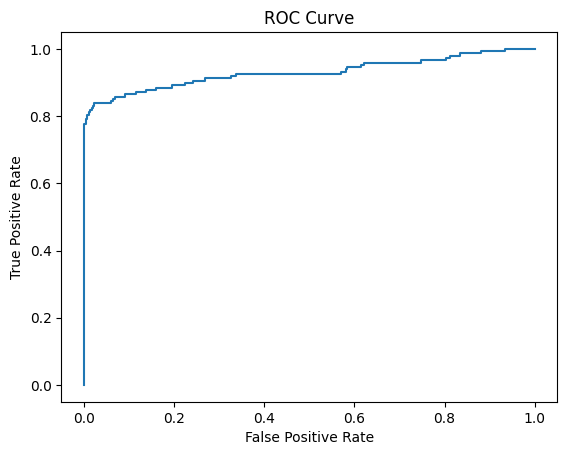

AUC: 0.9297275908888547


In [8]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_probs = model.predict_proba(X_test)[:,1]
fpr, tpr, _ = roc_curve(y_test, y_probs)
plt.plot(fpr, tpr)
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.show()
print("AUC:", roc_auc_score(y_test, y_probs))

A curva ROC é uma métrica usada em modelos de classificação. O gráfico mostra o desempenho do modelo em diferentes lineares de decisão (False Positive - Transações não-fraude que foram classificadas como fraude) True Positive - Quantas fraudes o modelo conseguiu identificar (recall).  

Cada ponto representa um limite diferente da decisão do modelo. Quanto mais próximo do lado esquerdo superior, melhor o modelo (alto recall, baixo erro).  

Se por um acaso a curva fosse totalmente diagonal, o modelo classificaria de modo aleatório entre fraude e não-fraude. AUC é a área sobre a curva. Quanto mais perto de 1 indica que o modelo está ótimo, já 0,5 é aleatório.

# **Precision Recall Curve**

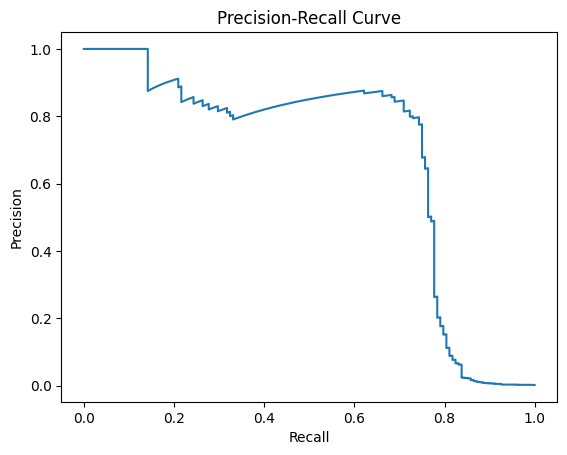

In [9]:
from sklearn.metrics import precision_recall_curve

precision, recall, _ = precision_recall_curve(y_test, y_probs)
plt.plot(recall, precision)
plt.title("Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.show()

Métrica fortemente usada para bases desbalanceadas. Apresenta o trade off entre as métricas.   

Quando precision = 1, o modelo aponta com 100% de total certeza tudo como não-fraude, mas o recall é nulo, pois as fraudes passam despercebidas.  

Quando o recall é muito alto, significa que o modelo está marcando muitas fraudes, inclusive as de não-fraudes.  

A medidas em que se mexem nesse números, aumentam a taxa de falsos positivos. Esse gráfico mostra melhor o comportamento do modelo do que a curva ROC

# **Balanceamento de dados**

In [10]:
#Undersampling - Reduzindo a classe majoritária (0) para ficar do mesmo tamanho que a classe minoritária (1).
# Modelo aprende melhor a identificar fraudes, porém reduz a qualidade do dado

fraudes = df[df["Class"] == 1]
normais = df[df["Class"] == 0].sample(len(fraudes), random_state=42)

df_under = pd.concat([fraudes, normais])

In [11]:
#Oversampling - Cria novos exemplos sintéticos da classe minoritária (1). Não perde dados, mas pode incluir ruídos

from imblearn.over_sampling import SMOTE
smote = SMOTE()

X_res, y_res = smote.fit_resample(X, y)

Para saber qual a melhor técnica, apenas testando

# **Random Forest**

É um modelo mais sofisticado. É um conjunto de várias árvores. Cada árvore vai aprender um padrão diferente dos dados e, no final, combina essa decisões. Aumenta sua precisão

In [12]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
n_estimators = 50, #number estimator - escolhendo 50 árvores
max_depth = 10, # limitando a profundidade das árvores para evitar overfitting (quando o modelo decora os dados de treino e não consegue classificar os dados de teste)
class_weight="balanced", # ajusta automaticamente o peso das classes, dando mais importância para a classe minoritária. Evita que o modelo ignore a classe minoritária
n_jobs=-1,
random_state=42
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.84      0.76      0.79       148

    accuracy                           1.00     85443
   macro avg       0.92      0.88      0.90     85443
weighted avg       1.00      1.00      1.00     85443



Para a Class 1:  
*recall = 0,76 - O modelo conseguiu definir 76% corretamente das fraudes (melhorou em 10% em relação a regressão logística)
*f1-score = Também melhorou


# **Pipeline**

Serve para organizar o fluxo de processamento. Primeiro realiza o StandartScaler e depois o LogisticRegression. Ajuda a evitar erros e manter consistência (serve tanto para o treino quanto para o teste)

In [13]:
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

# **Threshold**

Por padrão, o threshold do modelo é 0,5 (probabilidade maior que 0,5, ele classifica como fraude). Ao ajustar para 0,3, a probabilidade testada é de 30%. Objetivo de aumentar o recall, mesmo que isso gere mais falso positivos

In [14]:
threshold = 0.3
y_pred_custom = (y_probs > threshold).astype(int)
print(classification_report(y_test, y_pred_custom))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.85      0.71      0.77       148

    accuracy                           1.00     85443
   macro avg       0.92      0.85      0.89     85443
weighted avg       1.00      1.00      1.00     85443



# **XGBoost**

Constrói árvores de decisão em sequência, onde cada árvore nova tenta corrigir os erros e resíduos das previsões das árvores anteriores. Possui algoritmos embutidos para aprender automaticamente o melhor sentido de ramificação para valores nulos/faltantes.

In [15]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    scale_pos_weight=10,
    use_label_encoder = False,
    eval_metric="logloss"
)

xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [23:22:09] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [16]:
print(classification_report(y_test, y_pred_xgb))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.94      0.78      0.85       148

    accuracy                           1.00     85443
   macro avg       0.97      0.89      0.93     85443
weighted avg       1.00      1.00      1.00     85443



# **Importância das variáveis**

Quais variáveis influenciam mais no modelo

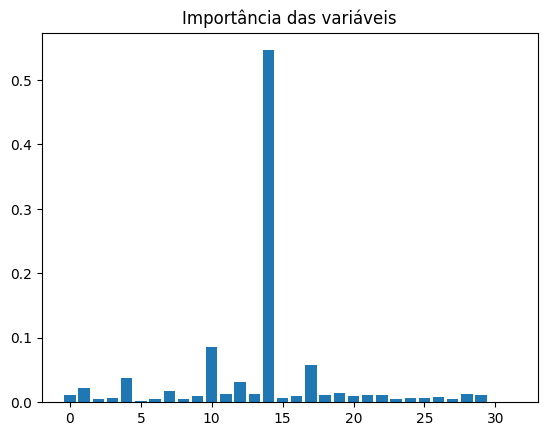

In [17]:
import matplotlib.pyplot as plt

importancias = xgb.feature_importances_
plt.bar(range(len(importancias)), importancias)
plt.title("Importância das variáveis")
plt.show()

# **Ajuste de hiperparâmetros**

Para testar várias combinações de parâmetros e encontrar a melhor, usa-se um GridSearchCV. O modelo tem configurações chamadas de hiperparâmetros (como max_depth e n_estimators no XGBoost), que não são aprendidos pelo modelo, mas precisam ser definidos pelo usuário. No param_grid são colocados parâmetros a serem testados. O melhor parâmetro, nesse projeto, é o recall, que aparece no scoring "recall".

In [18]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "max_depth": [3, 5],
    "n_estimators": [50, 100]
}

grid = GridSearchCV(
    XGBClassifier(eval_metric="logloss"),
    param_grid,
    scoring="recall", # escolher um parâmetro e colocar aqui
    cv=3
)

grid.fit(X_train, y_train)
print("Melhor modelo:", grid.best_params_)

Melhor modelo: {'max_depth': 5, 'n_estimators': 100}


# **Explicabilidade (SHAP)**

Explica como cada variável contribui para a decisão do modelo (a importância mostra as relevantes, o SHAP mostra o impacto de cada variável na previsão)

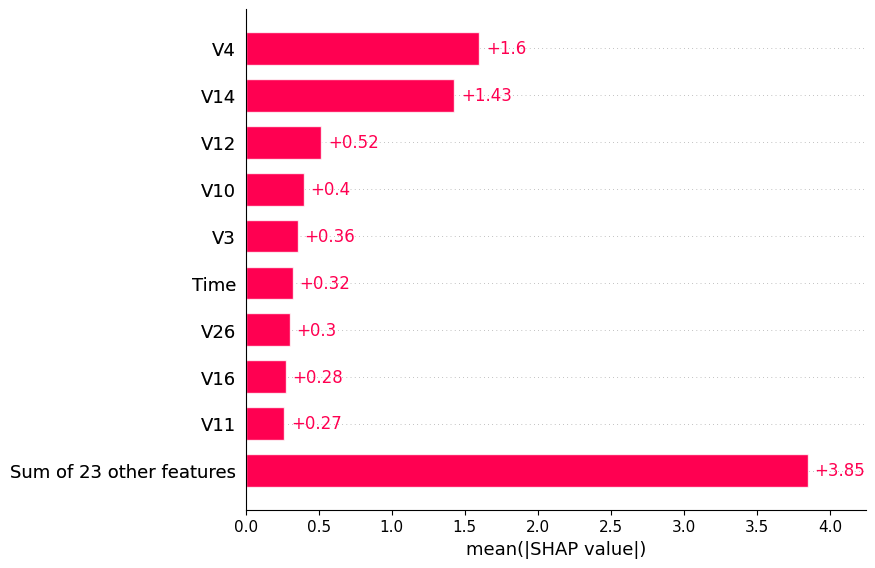

In [19]:
import shap

explainer = shap.Explainer(xgb)
shap_values = explainer(X_test[:100])
shap.plots.bar(shap_values)